# Apartment Rental Price Prediction

Notebook formatting of `../FIRST DRAFT MODEL.py`; the modeling code is identical.

We use shuffled five-fold CV (seed 42) and dollar RMSE consistently. Preprocessing is fitted within each fold. The test prices are unavailable and test rows are never used to fit or tune models.

Training/validation gaps help assess overfitting; high errors on both suggest underfitting. The selected CV score can be optimistic because the same folds guide tuning and selection.


## Imports


In [1]:
# First draft for apartment predictor

# 1. Import packages

# Core data handling
from pathlib import Path
from IPython.display import display
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings('ignore')

# Preprocessing + pipelines
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

# Validation tools
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import KFold, cross_validate, GridSearchCV

# Regression models
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (RandomForestRegressor, GradientBoostingRegressor,
                              HistGradientBoostingRegressor)

# Reproducibility: every random process uses this seed
RANDOM_STATE = 42
# Support the root script and its notebook copy in models/.
PROJECT_ROOT = (Path(__file__).resolve().parent if '__file__' in globals()
                else Path.cwd().parent if Path.cwd().name == 'models' else Path.cwd())



## Load and explore


Train shape: (7398, 10) | Test shape: (2467, 9)


,ID,price,bathrooms,bedrooms,square_feet,latitude,longitude,category,has_photo,state
0,2,925,1.0,0,116,47.6160,-122.3275,housing/rent/apartment,Thumbnail,WA
1,3,2475,1.0,0,130,40.7629,-73.9885,housing/rent/apartment,Thumbnail,NY
2,5,1695,1.0,0,190,37.7599,-122.4379,housing/rent/apartment,Thumbnail,CA
3,6,1560,1.0,1,200,35.0847,-77.0609,housing/rent/apartment,Thumbnail,NC
4,7,1560,1.0,1,200,35.0960,-77.0272,housing/rent/apartment,Thumbnail,NC


<class 'pandas.DataFrame'>
RangeIndex: 7398 entries, 0 to 7397
Data columns (total 10 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   ID           7398 non-null   int64  
 1   price        7398 non-null   int64  
 2   bathrooms    7398 non-null   float64
 3   bedrooms     7398 non-null   int64  
 4   square_feet  7398 non-null   int64  
 5   latitude     7398 non-null   float64
 6   longitude    7398 non-null   float64
 7   category     7398 non-null   str    
 8   has_photo    7398 non-null   str    
 9   state        7398 non-null   str    
dtypes: float64(3), int64(4), str(3)
memory usage: 811.5 KB


,count,mean,std,min,25%,50%,75%,max
price,7398.0,1462.805488,821.583589,200.0000,949.0000,1273.5000,1695.0000,8800.0000
bathrooms,7398.0,1.379832,0.602894,1.0000,1.0000,1.0000,2.0000,7.0000
bedrooms,7398.0,1.743850,0.936658,0.0000,1.0000,2.0000,2.0000,9.0000
square_feet,7398.0,940.935253,502.246805,116.0000,650.0000,807.5000,1100.0000,5921.0000
latitude,7398.0,37.647724,5.517342,21.3155,33.6047,38.7701,41.3498,61.5940
longitude,7398.0,-94.407727,15.722082,-158.0221,-98.5290,-93.6516,-81.6437,-70.3461


Missing values (train): 0
Missing values (test):  0

category: 3 unique values
category
housing/rent/apartment     7395
housing/rent/home             2
housing/rent/short_term       1
Name: count, dtype: int64

has_photo: 3 unique values
has_photo
Thumbnail    6566
Yes           693
No            139
Name: count, dtype: int64

state: 50 unique values
state
TX    1327
CA     688
WA     375
MD     341
NC     340
NJ     294
GA     271
FL     249
OH     232
CO     230
Name: count, dtype: int64

States in test but not in train: {'WY'}


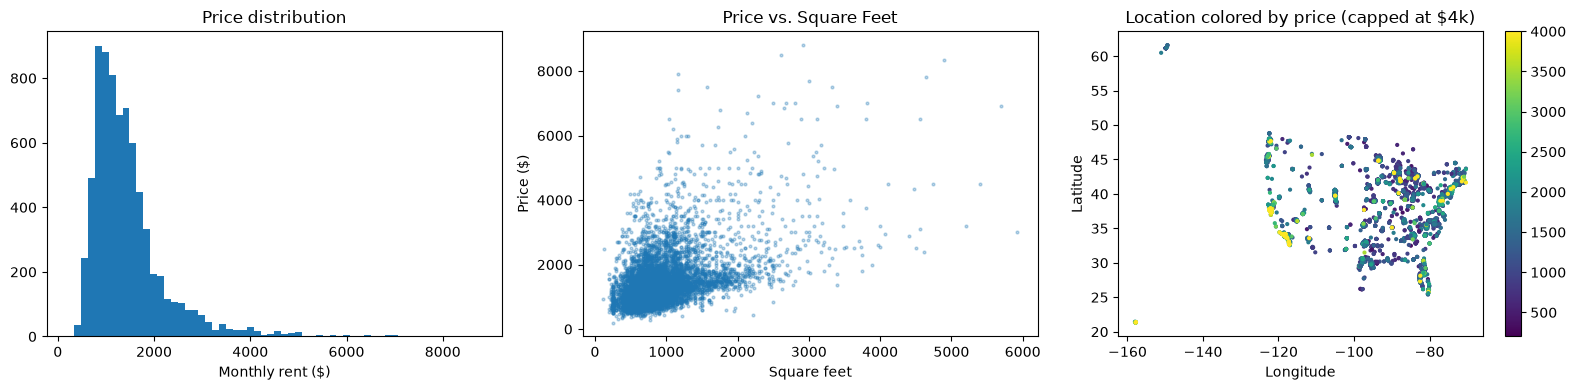

In [2]:
# 2. Load and inspect

# Load both datasets
df_train = pd.read_csv(PROJECT_ROOT / 'datasets' / 'challenge1_train.csv')
df_test  = pd.read_csv(PROJECT_ROOT / 'datasets' / 'challenge1_test.csv')   # used ONLY for final predictions

print('Train shape:', df_train.shape, '| Test shape:', df_test.shape)
display(df_train.head())
df_train.info()

# Quick peek at the numeric stats (skipping ID since it's just a useless tag)
display(df_train.drop(columns='ID').describe().T)

# Supposedly the data is clean, but let's double-check that no missing values snuck in
print('Missing values (train):', df_train.isna().sum().sum())
print('Missing values (test): ', df_test.isna().sum().sum())

# Let's see what's going on with the text categories
for col in ['category', 'has_photo', 'state']:
    print(f"\n{col}: {df_train[col].nunique()} unique values")
    print(df_train[col].value_counts().head(10))

# Catching any sneaky states in the test data that didn't show up during training
unseen_states = set(df_test['state']) - set(df_train['state'])
print('\nStates in test but not in train:', unseen_states)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# 1. Distribution of price
axes[0].hist(df_train['price'], bins=60)
axes[0].set_title('Price distribution')
axes[0].set_xlabel('Monthly rent ($)')

# 2. Price vs. square feet (size should be a strong driver)
axes[1].scatter(df_train['square_feet'], df_train['price'], s=4, alpha=0.3)
axes[1].set_title('Price vs. Square Feet')
axes[1].set_xlabel('Square feet'); axes[1].set_ylabel('Price ($)')

# 3. Location map colored by price (location should also be a strong driver)
sc = axes[2].scatter(df_train['longitude'], df_train['latitude'],
                     c=np.clip(df_train['price'], 0, 4000), s=4, cmap='viridis')
axes[2].set_title('Location colored by price (capped at $4k)')
axes[2].set_xlabel('Longitude'); axes[2].set_ylabel('Latitude')
plt.colorbar(sc, ax=axes[2])

plt.tight_layout()
plt.show()



## Feature relationships


In [3]:
# Correlation of numeric features with price
num_preview = ['price', 'bathrooms', 'bedrooms', 'square_feet', 'latitude', 'longitude']
display(df_train[num_preview].corr()[['price']].sort_values('price', ascending=False))

# Median price by state (top 10 most expensive states with at least 30 listings)
state_stats = df_train.groupby('state')['price'].agg(['count', 'median'])
display(state_stats[state_stats['count'] >= 30].sort_values('median', ascending=False).head(10))




,price
price,1.000000
square_feet,0.484285
bathrooms,0.444624
bedrooms,0.358349
latitude,0.039075
longitude,-0.192189


,count,median
state,,
CA,688,2325.0
MA,119,2274.0
DC,62,1966.0
NJ,294,1811.0
WA,375,1675.0
NY,56,1500.5
MD,341,1476.0
VA,149,1424.0
FL,249,1350.0


## Prepare features and validation


In [4]:
# PREPARE DATA

def add_features(df):
    """Create engineered features. Uses only values within each row,
    so applying it to train and test separately causes no data leakage."""
    df = df.copy()
    df['sqft_per_bed'] = df['square_feet'] / (df['bedrooms'] + 1)   # +1 avoids divide-by-zero for studios
    df['bath_per_bed'] = df['bathrooms'] / (df['bedrooms'] + 1)
    df['total_rooms']  = df['bedrooms'] + df['bathrooms']
    return df

DROP_COLS = ['ID', 'category']

# Adding training predictors and target
X = add_features(df_train.drop(columns=DROP_COLS + ['price']))
y = df_train['price']

# Test predictors (same transformations, no target available -_-)
X_test = add_features(df_test.drop(columns=DROP_COLS))

# Separate dtypes for preprocessing steps
cat_cols = X.select_dtypes(exclude='number').columns.tolist()   # text columns (works for object or string dtype)
num_cols = [c for c in X.columns if c not in cat_cols]

print('Categorical:', cat_cols)

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
SCORING = 'neg_root_mean_squared_error'   # sklearn maximizes scores, so RMSE is returned as a negative
print('Numeric:    ', num_cols)
print('X shape:', X.shape, '| X_test shape:', X_test.shape)



Categorical: ['has_photo', 'state']
Numeric:     ['bathrooms', 'bedrooms', 'square_feet', 'latitude', 'longitude', 'sqft_per_bed', 'bath_per_bed', 'total_rooms']
X shape: (7398, 10) | X_test shape: (2467, 10)


## Preprocessing pipeline


In [5]:
# Defining processes!
def make_preprocess():
    return ColumnTransformer([
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols),
        ('num', StandardScaler(), num_cols)
    ])

def make_pipe(model):
    """Wrap any regressor into a full preprocess -> model pipeline."""
    return Pipeline([
        ('preprocess', make_preprocess()),
        ('model', model)
    ])


## Baseline models


In [6]:
baseline_models = {
    'Linear Regression':   LinearRegression(),
    'Decision Tree':       DecisionTreeRegressor(random_state=RANDOM_STATE),
    'Random Forest':       RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE, n_jobs=1),
    'Gradient Boosting':   GradientBoostingRegressor(random_state=RANDOM_STATE),
    'Hist Gradient Boost': HistGradientBoostingRegressor(random_state=RANDOM_STATE),   # extra model
}

def evaluate(name, pipe):
    """Run 5-fold CV and return mean train/validation RMSE and fit time."""
    t0 = time.perf_counter()
    res = cross_validate(pipe, X, y, cv=cv, scoring=SCORING, return_train_score=True, n_jobs=4)
    return {
        'Model':          name,
        'Train_RMSE':     -res['train_score'].mean(),
        'CV_RMSE':        -res['test_score'].mean(),
        'CV_RMSE_std':    res['test_score'].std(),
        'Time_sec':       time.perf_counter() - t0,
    }

baseline_results = [evaluate(name, make_pipe(m)) for name, m in baseline_models.items()]
baseline_df = pd.DataFrame(baseline_results).sort_values('CV_RMSE').reset_index(drop=True)
baseline_df['Gap (CV - Train)'] = baseline_df['CV_RMSE'] - baseline_df['Train_RMSE']   # overfitting indicator
display(baseline_df.round(1))



,Model,Train_RMSE,CV_RMSE,CV_RMSE_std,Time_sec,Gap (CV - Train)
0,Hist Gradient Boost,308.0,415.5,28.5,2.7,107.5
1,Random Forest,162.6,429.2,33.5,7.5,266.6
2,Gradient Boosting,399.7,457.2,26.1,1.2,57.6
3,Linear Regression,518.8,525.4,27.9,1.9,6.6
4,Decision Tree,40.7,565.8,48.2,0.2,525.1


## Baseline comparison


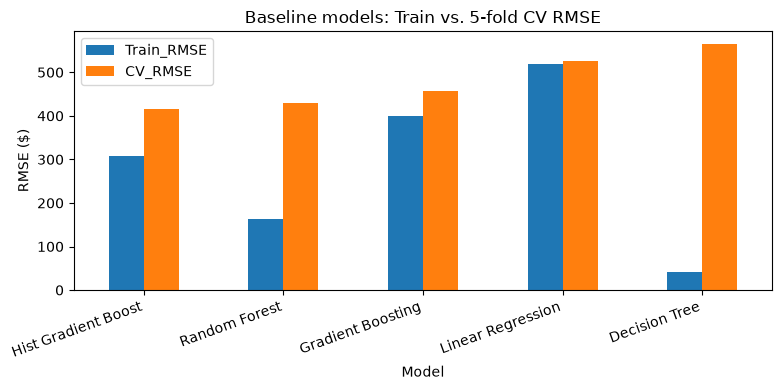

In [7]:
# Visual comparison of train vs. validation RMSE

ax = baseline_df.set_index('Model')[['Train_RMSE', 'CV_RMSE']].plot(kind='bar', figsize=(8, 4))
ax.set_ylabel('RMSE ($)')
ax.set_title('Baseline models: Train vs. 5-fold CV RMSE')
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.show()



## Grid Search


In [8]:
# 7. Improve selected models with Grid Search
# Reuse the same shuffled five folds and dollar RMSE for every comparison.
# Pipelines fit encoding/scaling only on each fold's training rows.
# These tuning scores guide selection; they are not an independent test estimate.
param_grids = {
    'Decision Tree': (
        DecisionTreeRegressor(random_state=RANDOM_STATE),
        {'model__max_depth': [8, 12, 16, None],
         'model__min_samples_leaf': [1, 5, 10]},
    ),
    'Random Forest': (
        RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE, n_jobs=1),
        {'model__max_features': [0.5, 1.0], 'model__min_samples_leaf': [1, 3]},
    ),
    'Gradient Boosting': (
        GradientBoostingRegressor(random_state=RANDOM_STATE),
        {'model__n_estimators': [300], 'model__learning_rate': [0.05, 0.1],
         'model__max_depth': [3, 5], 'model__subsample': [0.8, 1.0]},
    ),
    'Hist Gradient Boost': (
        HistGradientBoostingRegressor(random_state=RANDOM_STATE),
        {'model__learning_rate': [0.05, 0.1], 'model__max_iter': [300, 600],
         'model__max_leaf_nodes': [31, 63]},
    ),
}

grid_searches = {}
tuned_rows = []
for name, (model, grid) in param_grids.items():
    start = time.perf_counter()
    search = GridSearchCV(
        make_pipe(model), grid, cv=cv, scoring=SCORING,
        return_train_score=True, n_jobs=4, refit=True, error_score='raise'
    )
    search.fit(X, y)
    grid_searches[name] = search
    best = search.best_index_
    tuned_rows.append({
        'Model': name + ' (tuned)',
        'Train_RMSE': -search.cv_results_['mean_train_score'][best],
        'CV_RMSE': -search.best_score_,
        'CV_RMSE_std': search.cv_results_['std_test_score'][best],
        'Time_sec': time.perf_counter() - start,
    })
    print(name, 'best parameters:', search.best_params_, flush=True)



Decision Tree best parameters: {'model__max_depth': 16, 'model__min_samples_leaf': 10}
Random Forest best parameters: {'model__max_features': 0.5, 'model__min_samples_leaf': 3}
Gradient Boosting best parameters: {'model__learning_rate': 0.1, 'model__max_depth': 5, 'model__n_estimators': 300, 'model__subsample': 0.8}
Hist Gradient Boost best parameters: {'model__learning_rate': 0.05, 'model__max_iter': 300, 'model__max_leaf_nodes': 31}


## Final comparison and model justification


In [9]:
# 8. Compare all models and select the final model
comparison_df = pd.concat([
    baseline_df.drop(columns='Gap (CV - Train)'), pd.DataFrame(tuned_rows)
], ignore_index=True).sort_values('CV_RMSE').reset_index(drop=True)
comparison_df['Gap (CV - Train)'] = comparison_df['CV_RMSE'] - comparison_df['Train_RMSE']
display(comparison_df.round(2))

# Include the baseline candidates: tuning is not guaranteed to improve them.
candidate_models = {name: make_pipe(model) for name, model in baseline_models.items()}
candidate_models.update({name + ' (tuned)': search.best_estimator_
                         for name, search in grid_searches.items()})
best_row = comparison_df.iloc[0]
best_name = best_row['Model']
final_model = candidate_models[best_name]
start = time.perf_counter()
final_model.fit(X, y)  # Fit the selected pipeline on every labeled row.
final_fit_seconds = time.perf_counter() - start

# Explain the actual selection, including all five assignment criteria.
model_step = final_model.named_steps['model']
params = model_step.get_params()
if isinstance(model_step, LinearRegression):
    complexity = 'a linear model with one coefficient per transformed feature'
    interpretability = 'Its coefficients are inspectable, although correlated features complicate interpretation.'
elif isinstance(model_step, DecisionTreeRegressor):
    complexity = f'a single tree of depth {model_step.get_depth()} with {model_step.get_n_leaves()} leaves'
    interpretability = 'Its decision paths can be inspected, but large trees are difficult to summarize.'
elif isinstance(model_step, HistGradientBoostingRegressor):
    complexity = f"a boosting ensemble with {model_step.n_iter_} iterations and max_leaf_nodes={params['max_leaf_nodes']}"
    interpretability = 'It is less directly interpretable than a linear model or one tree; permutation importance can summarize feature influence.'
else:
    complexity = f"an ensemble of {params['n_estimators']} trees with max_depth={params['max_depth']}"
    interpretability = 'It is less directly interpretable than a linear model or one tree; feature importances can summarize influence but do not establish causation.'

print(f"Selected model: {best_name}. Its mean validation RMSE was ${best_row['CV_RMSE']:.2f} "
      f"(fold standard deviation ${best_row['CV_RMSE_std']:.2f}), the lowest among all candidates. "
      f"Training RMSE was ${best_row['Train_RMSE']:.2f}, giving a train-validation gap of "
      f"${best_row['Gap (CV - Train)']:.2f}; a positive gap indicates remaining overfitting. "
      f"The selected estimator is {complexity}. Its evaluation/search took "
      f"{best_row['Time_sec']:.1f}s, while the final full-data fit took {final_fit_seconds:.1f}s. "
      f"We accept this computational cost to prioritize validation RMSE. {interpretability} "
      "The CV scores guided hyperparameter and model selection, so the winning score may be optimistic. "
      "Small differences between candidates do not establish statistical significance; "
      "performance on the hidden test prices remains unknown.")



,Model,Train_RMSE,CV_RMSE,CV_RMSE_std,Time_sec,Gap (CV - Train)
0,Gradient Boosting (tuned),206.67,404.82,32.73,27.29,198.15
1,Hist Gradient Boost (tuned),282.62,411.89,28.20,68.89,129.26
2,Hist Gradient Boost,307.97,415.47,28.46,2.73,107.50
3,Random Forest (tuned),287.07,425.29,30.36,16.67,138.22
4,Random Forest,162.62,429.24,33.54,7.48,266.62
5,Gradient Boosting,399.68,457.24,26.15,1.24,57.56
6,Decision Tree (tuned),395.83,501.50,30.75,0.72,105.67
7,Linear Regression,518.82,525.41,27.88,1.88,6.59
8,Decision Tree,40.67,565.79,48.17,0.19,525.12


Selected model: Gradient Boosting (tuned). Its mean validation RMSE was $404.82 (fold standard deviation $32.73), the lowest among all candidates. Training RMSE was $206.67, giving a train-validation gap of $198.15; a positive gap indicates remaining overfitting. The selected estimator is an ensemble of 300 trees with max_depth=5. Its evaluation/search took 27.3s, while the final full-data fit took 3.7s. We accept this computational cost to prioritize validation RMSE. It is less directly interpretable than a linear model or one tree; feature importances can summarize influence but do not establish causation. The CV scores guided hyperparameter and model selection, so the winning score may be optimistic. Small differences between candidates do not establish statistical significance; performance on the hidden test prices remains unknown.


## Final predictions


In [10]:
# 9. Generate the required predictions
predictions = pd.DataFrame({'ID': df_test['ID'], 'price': final_model.predict(X_test)})
assert list(predictions.columns) == ['ID', 'price']
assert len(predictions) == len(df_test) == 2467
assert predictions['ID'].is_unique
assert predictions['ID'].equals(df_test['ID'])
assert np.isfinite(predictions['price']).all()
predictions.to_csv(PROJECT_ROOT / 'predictions.csv', index=False)
print('Saved predictions.csv:', predictions.shape)
display(predictions.head())
display(predictions['price'].describe())


Saved predictions.csv: (2467, 2)


,ID,price
0,1,1467.472511
1,4,1797.476987
2,9,641.591731
3,11,783.179455
4,13,738.743153


count    2467.000000
mean     1469.288897
std       751.562018
min       467.829575
25%      1009.906994
50%      1262.904617
75%      1650.593987
max      7510.579917
Name: price, dtype: float64